# Cell 1 – Environment and checkpoint verification

In [2]:

# ============================================================
# FISHVISION V3 — CELL 1
# ENVIRONMENT + HUGGING FACE + CHECKPOINT AUDIT
# ============================================================

import os
import json
import torch
import pandas as pd
from pathlib import Path
from huggingface_hub import HfApi, hf_hub_download
from kaggle_secrets import UserSecretsClient

# ---------------- CONFIGURATION ----------------

REPO_ID = "bandaruadarsh/FishVision-V2-Backup"
REPO_TYPE = "model"

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
api = HfApi(token=HF_TOKEN)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("=" * 65)
print("FISHVISION V3 — FINAL VERIFICATION")
print("=" * 65)

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ---------------- VERIFY HF ACCESS ----------------

repo_info = api.repo_info(
    repo_id=REPO_ID,
    repo_type=REPO_TYPE
)

print("\nHF repository access verified.")
print("Repository:", repo_info.id)

# ---------------- LIST ALL REMOTE FILES ----------------

remote_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type=REPO_TYPE
)

print("\nTotal remote files:", len(remote_files))

# ---------------- EXPECTED FIVE MODELS ----------------

model_specs = {
    "DINOv2": {
        "architecture": "vit_base_patch14_reg4_dinov2.lvd142m",
        "resolution": 518,
        "checkpoint_candidates": [
            "experiments/V2.1/DINOv2/DINOv2_V2_1_Best.pth"
        ]
    },
    "ViT-B/16": {
        "architecture": "vit_base_patch16_224",
        "resolution": 224,
        "checkpoint_candidates": []
    },
    "Swin Tiny": {
        "architecture": "swin_tiny_patch4_window7_224",
        "resolution": 224,
        "checkpoint_candidates": []
    },
    "ConvNeXt Tiny": {
        "architecture": "convnext_tiny",
        "resolution": 224,
        "checkpoint_candidates": []
    },
    "MobileNetV3": {
        "architecture": "mobilenetv3_large_100",
        "resolution": 224,
        "checkpoint_candidates": [
            "experiments/V2.1/MobileNetV3/MobileNetV3_V2_1_Best.pth"
        ]
    }
}

# Find candidate files using model-related names
for model_name, spec in model_specs.items():

    if not spec["checkpoint_candidates"]:

        keywords = {
            "ViT-B/16": ["vit", "best"],
            "Swin Tiny": ["swin", "best"],
            "ConvNeXt Tiny": ["convnext", "best"]
        }.get(model_name, [])

        matches = [
            f for f in remote_files
            if all(k.lower() in f.lower() for k in keywords)
            and f.lower().endswith((".pth", ".pt"))
        ]

        spec["checkpoint_candidates"] = matches

# ---------------- AUDIT CHECKPOINTS ----------------

inventory = []

for model_name, spec in model_specs.items():

    candidates = spec["checkpoint_candidates"]

    for checkpoint in candidates:

        exists = checkpoint in remote_files

        inventory.append({
            "model": model_name,
            "architecture": spec["architecture"],
            "resolution": spec["resolution"],
            "checkpoint": checkpoint,
            "remote_exists": exists
        })

    if not candidates:
        inventory.append({
            "model": model_name,
            "architecture": spec["architecture"],
            "resolution": spec["resolution"],
            "checkpoint": "NOT FOUND",
            "remote_exists": False
        })

inventory_df = pd.DataFrame(inventory)

print("\n========== CHECKPOINT INVENTORY ==========")
display(inventory_df)

# ---------------- SEARCH IMPORTANT ARTIFACTS ----------------

categories = {
    "training_history": ["history", "training"],
    "predictions": ["prediction", "logit"],
    "confusion_matrices": ["confusion"],
    "class_reports": ["class_report", "classification_report"],
    "configs": ["config"],
    "benchmarks": ["benchmark"]
}

print("\n========== ARTIFACT SEARCH ==========")

artifact_inventory = {}

for category, keywords in categories.items():

    matches = [
        f for f in remote_files
        if any(k in f.lower() for k in keywords)
    ]

    artifact_inventory[category] = matches

    print(f"\n{category}: {len(matches)} files")

    for f in matches[:15]:
        print("  ", f)

# ---------------- SAVE AUDIT ----------------

os.makedirs("/kaggle/working/FishVision_Verification", exist_ok=True)

output_dir = Path("/kaggle/working/FishVision_Verification")

inventory_df.to_csv(
    output_dir / "checkpoint_inventory.csv",
    index=False
)

with open(output_dir / "artifact_inventory.json", "w") as f:
    json.dump(artifact_inventory, f, indent=4)

summary = {
    "device": DEVICE,
    "torch_version": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "repository": REPO_ID,
    "total_remote_files": len(remote_files),
    "checkpoint_inventory": inventory
}

with open(output_dir / "cell1_audit_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("\nCELL 1 COMPLETED.")
print("Audit files saved:", output_dir)
print("\nDo not start training. This cell only audits existing artifacts.")


FISHVISION V3 — FINAL VERIFICATION
Device: cuda
PyTorch: 2.11.0+cu130
GPU: Tesla T4

HF repository access verified.
Repository: bandaruadarsh/FishVision-V2-Backup

Total remote files: 73

========== CHECKPOINT INVENTORY ==========


,model,architecture,resolution,checkpoint,remote_exists
0,DINOv2,vit_base_patch14_reg4_dinov2.lvd142m,518,experiments/V2.1/DINOv2/DINOv2_V2_1_Best.pth,True
1,ViT-B/16,vit_base_patch16_224,224,checkpoints/ViT_B16_V2_Best_152.pth,True
2,ViT-B/16,vit_base_patch16_224,224,experiments/V2.1/ViT_B16/ViT_B16_V2_1_Best.pth,True
3,Swin Tiny,swin_tiny_patch4_window7_224,224,checkpoints/Swin_Tiny_Best_152.pth,True
4,Swin Tiny,swin_tiny_patch4_window7_224,224,experiments/V2.1/Swin_Tiny/Swin_Tiny_V2_1_Best...,True
5,ConvNeXt Tiny,convnext_tiny,224,checkpoints/ConvNeXt_Tiny_Best_152.pth,True
6,ConvNeXt Tiny,convnext_tiny,224,experiments/V2.1/ConvNeXt_Tiny/ConvNeXt_Tiny_V...,True
7,MobileNetV3,mobilenetv3_large_100,224,experiments/V2.1/MobileNetV3/MobileNetV3_V2_1_...,True



========== ARTIFACT SEARCH ==========

training_history: 9 files
   experiments/V2.1/ConvNeXt_Tiny/training_history.csv
   experiments/V2.1/DINOv2/training_history.csv
   experiments/V2.1/MobileNetV3/training_history.csv
   experiments/V2.1/Swin_Tiny/training_history.csv
   experiments/V2.1/ViT_B16/training_history.csv
   experiments/V3/Distillation/distillation_training_history.csv
   reports/ConvNeXt_Tiny_V2_Final_Evaluation/training_history.csv
   reports/MobileNetV3_V2_Final_Evaluation/training_history.csv
   reports/Swin_Tiny_V2_Final_Evaluation/training_history.csv

predictions: 6 files
   experiments/V3/Distillation/dinov2_train_logits.pt
   reports/ConvNeXt_Tiny_V2_Final_Evaluation/test_predictions.csv
   reports/FishVision_V2_DINOv2_Recovered/DINOv2_test_predictions.csv
   reports/MobileNetV3_V2_Final_Evaluation/test_predictions.csv
   reports/Swin_Tiny_V2_Final_Evaluation/test_predictions.csv
   reports/ViT_B16_V2_Final_Evaluation/ViT_B16_test_predictions.csv

confusion_matr

# Cell 2 — Checkpoint, prediction and training metadata verification

In [3]:

# ============================================================
# FISHVISION V3 — CELL 2
# CHECKPOINT + PREDICTION + TRAINING HISTORY INSPECTION
# ============================================================

import os
import json
import torch
import pandas as pd
from pathlib import Path
from huggingface_hub import HfApi, hf_hub_download
from kaggle_secrets import UserSecretsClient

REPO_ID = "bandaruadarsh/FishVision-V2-Backup"
HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
api = HfApi(token=HF_TOKEN)

REMOTE_FILES = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="model"
)

OUTPUT_DIR = Path("/kaggle/working/FishVision_Verification")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Prefer the consistent V2.1 experiment checkpoints
MODEL_SEARCH = {
    "DINOv2": {
        "preferred": "experiments/V2.1/DINOv2/DINOv2_V2_1_Best.pth",
        "keywords": ["dinov2", "best"]
    },
    "ViT-B16": {
        "preferred": "experiments/V2.1/ViT_B16/ViT_B16_V2_1_Best.pth",
        "keywords": ["vit_b16", "best"]
    },
    "Swin_Tiny": {
        "preferred": "experiments/V2.1/Swin_Tiny/Swin_Tiny_V2_1_Best.pth",
        "keywords": ["swin_tiny", "best"]
    },
    "ConvNeXt_Tiny": {
        "preferred": "experiments/V2.1/ConvNeXt_Tiny/ConvNeXt_Tiny_V2_1_Best.pth",
        "keywords": ["convnext_tiny", "best"]
    },
    "MobileNetV3": {
        "preferred": "experiments/V2.1/MobileNetV3/MobileNetV3_V2_1_Best.pth",
        "keywords": ["mobilenetv3", "best"]
    }
}

# ---------------- RESOLVE CHECKPOINTS ----------------

resolved = {}

for model, spec in MODEL_SEARCH.items():

    preferred = spec["preferred"]

    if preferred in REMOTE_FILES:
        resolved[model] = preferred
        continue

    candidates = [
        f for f in REMOTE_FILES
        if all(k.lower() in f.lower() for k in spec["keywords"])
        and f.lower().endswith((".pth", ".pt"))
    ]

    if candidates:
        candidates.sort(
            key=lambda x: (
                "experiments/V2.1/" not in x,
                len(x)
            )
        )
        resolved[model] = candidates[0]
    else:
        resolved[model] = None

print("========== RESOLVED CHECKPOINTS ==========")

for model, path in resolved.items():
    print(model, ":", path)

# ---------------- INSPECT CHECKPOINTS ----------------

checkpoint_details = []

for model, remote_path in resolved.items():

    if remote_path is None:
        print("\nMISSING CHECKPOINT:", model)
        continue

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=remote_path,
        repo_type="model",
        token=HF_TOKEN
    )

    checkpoint = torch.load(
        local_path,
        map_location="cpu",
        weights_only=False
    )

    print("\n" + "=" * 60)
    print("MODEL:", model)
    print("FILE:", remote_path)
    print("SIZE MB:", round(os.path.getsize(local_path) / 1e6, 2))

    if isinstance(checkpoint, dict):

        print("CHECKPOINT KEYS:", list(checkpoint.keys()))

        for key in [
            "architecture",
            "num_classes",
            "image_size",
            "best_epoch",
            "epoch",
            "validation_metrics"
        ]:
            if key in checkpoint:
                print(key, ":", checkpoint[key])

        state = (
            checkpoint.get("model_state_dict")
            or checkpoint.get("state_dict")
        )

        if state is not None:
            print("STATE DICT TENSORS:", len(state))
            print("FIRST 8 STATE KEYS:", list(state.keys())[:8])
        else:
            print("No standard state_dict key found.")

    else:
        print("Checkpoint object type:", type(checkpoint))

    checkpoint_details.append({
        "model": model,
        "remote_path": remote_path,
        "size_mb": os.path.getsize(local_path) / 1e6,
        "checkpoint_keys": (
            list(checkpoint.keys())
            if isinstance(checkpoint, dict) else []
        )
    })

    del checkpoint

# ---------------- INSPECT PREDICTION FILES ----------------

prediction_files = [
    f for f in REMOTE_FILES
    if "prediction" in f.lower()
    and f.lower().endswith(".csv")
]

print("\n" + "=" * 60)
print("SAVED TEST PREDICTION FILE SCHEMAS")
print("=" * 60)

prediction_details = []

for remote_path in prediction_files:

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=remote_path,
        repo_type="model",
        token=HF_TOKEN
    )

    df = pd.read_csv(local_path)

    print("\nFILE:", remote_path)
    print("ROWS:", len(df))
    print("COLUMNS:", list(df.columns))
    print(df.head(3).to_string(index=False))

    prediction_details.append({
        "file": remote_path,
        "rows": len(df),
        "columns": list(df.columns)
    })

# ---------------- INSPECT TRAINING HISTORIES ----------------

history_files = [
    f for f in REMOTE_FILES
    if "training_history.csv" in f.lower()
]

print("\n" + "=" * 60)
print("TRAINING HISTORY SCHEMAS")
print("=" * 60)

history_details = []

for remote_path in history_files:

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=remote_path,
        repo_type="model",
        token=HF_TOKEN
    )

    df = pd.read_csv(local_path)

    print("\nFILE:", remote_path)
    print("ROWS:", len(df))
    print("COLUMNS:", list(df.columns))
    print(df.head(2).to_string(index=False))

    history_details.append({
        "file": remote_path,
        "rows": len(df),
        "columns": list(df.columns)
    })

# ---------------- INSPECT PREPROCESSING CONFIG ----------------

preprocess_path = "configs/preprocessing_configs.json"

if preprocess_path in REMOTE_FILES:

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=preprocess_path,
        repo_type="model",
        token=HF_TOKEN
    )

    print("\n========== PREPROCESSING CONFIG ==========")

    with open(local_path) as f:
        preprocessing = json.load(f)

    print(json.dumps(preprocessing, indent=2))

# ---------------- SAVE INSPECTION SUMMARY ----------------

inspection = {
    "resolved_checkpoints": resolved,
    "checkpoint_details": checkpoint_details,
    "prediction_files": prediction_details,
    "training_histories": history_details
}

summary_path = OUTPUT_DIR / "cell2_metadata_inspection.json"

with open(summary_path, "w") as f:
    json.dump(inspection, f, indent=2, default=str)

print("\n" + "=" * 60)
print("CELL 2 COMPLETED")
print("Metadata inspection saved:", summary_path)
print("No training or checkpoint modifications performed.")
print("=" * 60)


========== RESOLVED CHECKPOINTS ==========
DINOv2 : experiments/V2.1/DINOv2/DINOv2_V2_1_Best.pth
ViT-B16 : experiments/V2.1/ViT_B16/ViT_B16_V2_1_Best.pth
Swin_Tiny : experiments/V2.1/Swin_Tiny/Swin_Tiny_V2_1_Best.pth
ConvNeXt_Tiny : experiments/V2.1/ConvNeXt_Tiny/ConvNeXt_Tiny_V2_1_Best.pth
MobileNetV3 : experiments/V2.1/MobileNetV3/MobileNetV3_V2_1_Best.pth


experiments/V2.1/DINOv2/DINOv2_V2_1_Best(…): reconstructing file:   0%|          |  0.00B /  347MB            

experiments/V2.1/DINOv2/DINOv2_V2_1_Best(…): downloading bytes:           |  0.00B            


MODEL: DINOv2
FILE: experiments/V2.1/DINOv2/DINOv2_V2_1_Best.pth
SIZE MB: 346.87
CHECKPOINT KEYS: ['model_state_dict', 'class_to_idx', 'num_classes', 'architecture', 'image_size', 'baseline_macro_f1', 'best_macro_f1', 'best_epoch']
architecture : vit_base_patch14_reg4_dinov2.lvd142m
num_classes : 152
image_size : 518
best_epoch : 1
STATE DICT TENSORS: 177
FIRST 8 STATE KEYS: ['cls_token', 'reg_token', 'pos_embed', 'patch_embed.proj.weight', 'patch_embed.proj.bias', 'blocks.0.norm1.weight', 'blocks.0.norm1.bias', 'blocks.0.attn.qkv.weight']


experiments/V2.1/ViT_B16/ViT_B16_V2_1_Be(…): reconstructing file:   0%|          |  0.00B /  344MB            

experiments/V2.1/ViT_B16/ViT_B16_V2_1_Be(…): downloading bytes:           |  0.00B            

... (36 outputs left out)

training_history.csv:   0%|          | 0.00/1.96k [00:00<?, ?B/s]


FILE: reports/Swin_Tiny_V2_Final_Evaluation/training_history.csv
ROWS: 12
COLUMNS: ['epoch', 'train_loss', 'train_accuracy', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_weighted_f1', 'val_loss']
 epoch  train_loss  train_accuracy  val_accuracy  val_macro_precision  val_macro_recall  val_macro_f1  val_weighted_f1  val_loss
     1    3.580026        0.398536      0.688151             0.509796          0.484585      0.460595         0.683411  2.250311
     2    2.120044        0.721757      0.762055             0.618321          0.591713      0.578799         0.760174  1.970757


preprocessing_configs.json:   0%|          | 0.00/1.86k [00:00<?, ?B/s]


========== PREPROCESSING CONFIG ==========
{
  "DINOv2": {
    "input_size": 518,
    "transform": [
      "Resize((518, 518))",
      "ToTensor()",
      "Normalize(ImageNet mean and standard deviation)"
    ],
    "reproduction_status": "Exact accuracy match",
    "accuracy": 93.8954
  },
  "ViT-B/16": {
    "input_size": 224,
    "transform": [
      "Resize(256)",
      "CenterCrop(224)",
      "ToTensor()",
      "Normalize(ImageNet mean and standard deviation)"
    ],
    "reproduction_status": "Exact accuracy match",
    "accuracy": 88.3348
  },
  "Swin Tiny": {
    "input_size": 224,
    "transform": [
      "Resize(256)",
      "CenterCrop(224)",
      "ToTensor()",
      "Normalize(ImageNet mean and standard deviation)"
    ],
    "reproduction_status": "Exact accuracy match",
    "accuracy": 85.1315
  },
  "ConvNeXt Tiny": {
    "input_size": 224,
    "transform": [
      "Resize(256)",
      "CenterCrop(224)",
      "ToTensor()",
      "Normalize(ImageNet mean and standard

# Cell 3 — Five-model final test evaluation

In [6]:

# ============================================================
# FISHVISION V3 — CELL 3
# FIVE ORIGINAL MODELS: FINAL TEST EVALUATION
# ============================================================

import os
import gc
import json
import time
import numpy as np
import pandas as pd
import torch
import timm

from pathlib import Path
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader


from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

from huggingface_hub import HfApi, hf_hub_download
from kaggle_secrets import UserSecretsClient

# ---------------- CONFIGURATION ----------------

from pathlib import Path

possible_roots = [
    Path("/kaggle/input/datasets/adarshbandaru/fishvision-152-classes"),
    Path("/kaggle/input/datasets/adarsh888500000000/fishvision-152-classes"),
]

DATASET_ROOT = next(
    (
        str(p) for p in possible_roots
        if all((p / s).is_dir() for s in ["train", "val", "test"])
    ),
    None
)

if DATASET_ROOT is None:
    raise FileNotFoundError("FishVision dataset not found.")

TEST_DIR = str(Path(DATASET_ROOT) / "test")

print("Verified dataset:", DATASET_ROOT)
print("Test directory:", TEST_DIR)

# ---------------- MODEL CONFIGURATIONS ----------------

MODELS = {
    "DINOv2": {
        "architecture": "vit_base_patch14_reg4_dinov2.lvd142m",
        "checkpoint": "experiments/V2.1/DINOv2/DINOv2_V2_1_Best.pth",
        "image_size": 518,
        "batch_size": 8,
        "transform": "dinov2"
    },
    "ViT_B16": {
        "architecture": "vit_base_patch16_224",
        "checkpoint": "experiments/V2.1/ViT_B16/ViT_B16_V2_1_Best.pth",
        "image_size": 224,
        "batch_size": 32,
        "transform": "standard"
    },
    "Swin_Tiny": {
        "architecture": "swin_tiny_patch4_window7_224",
        "checkpoint": "experiments/V2.1/Swin_Tiny/Swin_Tiny_V2_1_Best.pth",
        "image_size": 224,
        "batch_size": 32,
        "transform": "standard"
    },
    "ConvNeXt_Tiny": {
        "architecture": "convnext_tiny",
        "checkpoint": "experiments/V2.1/ConvNeXt_Tiny/ConvNeXt_Tiny_V2_1_Best.pth",
        "image_size": 224,
        "batch_size": 32,
        "transform": "standard"
    },
    "MobileNetV3": {
        "architecture": "mobilenetv3_large_100",
        "checkpoint": "experiments/V2.1/MobileNetV3/MobileNetV3_V2_1_Best.pth",
        "image_size": 224,
        "batch_size": 32,
        "transform": "standard"
    }
}

# ---------------- CANONICAL MAPPING ----------------

mapping_path = hf_hub_download(
    repo_id=REPO_ID,
    filename="configs/class_mapping.json",
    repo_type="model",
    token=HF_TOKEN
)

with open(mapping_path) as f:
    mapping_data = json.load(f)

class_to_idx = mapping_data["class_to_idx"]
raw_idx_to_class = mapping_data["idx_to_class"]

if isinstance(raw_idx_to_class, list):
    idx_to_class = {
        i: name for i, name in enumerate(raw_idx_to_class)
    }
else:
    idx_to_class = {
        int(k): v for k, v in raw_idx_to_class.items()
    }

NUM_CLASSES = len(class_to_idx)
class_names = [idx_to_class[i] for i in range(NUM_CLASSES)]

assert NUM_CLASSES == 152

print("Canonical classes:", NUM_CLASSES)

# ---------------- TEST DATASET ----------------

TEST_DIR = os.path.join(DATASET_ROOT, "test")
assert os.path.isdir(TEST_DIR), TEST_DIR

standard_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

dinov2_transform = transforms.Compose([
    transforms.Resize((518, 518)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

class CanonicalFishDataset(Dataset):

    def __init__(self, root, transform):
        ds = datasets.ImageFolder(root)

        self.samples = []
        self.transform = transform

        for path, _ in ds.samples:
            class_name = Path(path).parent.name

            if class_name not in class_to_idx:
                raise ValueError(
                    f"Unknown test class: {class_name}"
                )

            self.samples.append(
                (path, class_to_idx[class_name])
            )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]

        with Image.open(path) as im:
            image = im.convert("RGB")

        return self.transform(image), label

# ---------------- BACKUP FUNCTION ----------------

def upload_verify(local_path, remote_path):

    api.upload_file(
        path_or_fileobj=str(local_path),
        path_in_repo=remote_path,
        repo_id=REPO_ID,
        repo_type="model",
        commit_message=f"FishVision V2.1 final evaluation: {Path(local_path).name}"
    )

    downloaded = hf_hub_download(
        repo_id=REPO_ID,
        filename=remote_path,
        repo_type="model",
        token=HF_TOKEN,
        force_download=True
    )

    assert os.path.getsize(downloaded) > 0
    print("VERIFIED:", remote_path)

# ---------------- EVALUATION LOOP ----------------

all_summaries = []
all_artifacts = []

for model_name, config in MODELS.items():

    print("\n" + "=" * 65)
    print("EVALUATING:", model_name)
    print("=" * 65)

    checkpoint_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=config["checkpoint"],
        repo_type="model",
        token=HF_TOKEN
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    # Verify architecture and canonical mapping
    stored_arch = checkpoint.get("architecture")

    if stored_arch is not None:
        assert stored_arch == config["architecture"], (
            f"Architecture mismatch: {stored_arch}"
        )

    stored_mapping = checkpoint.get("class_to_idx")

    if stored_mapping is not None:
        assert stored_mapping == class_to_idx, (
            f"Class mapping mismatch for {model_name}"
        )

    stored_num = checkpoint.get("num_classes")

    if stored_num is not None:
        assert stored_num == NUM_CLASSES

    model = timm.create_model(
        config["architecture"],
        pretrained=False,
        num_classes=NUM_CLASSES
    )

    state_dict = checkpoint.get(
        "model_state_dict",
        checkpoint.get("state_dict")
    )

    assert state_dict is not None

    model.load_state_dict(state_dict, strict=True)
    model = model.to(DEVICE).eval()

    transform = (
        dinov2_transform
        if config["transform"] == "dinov2"
        else standard_transform
    )

    test_dataset = CanonicalFishDataset(
        TEST_DIR,
        transform
    )

    loader = DataLoader(
        test_dataset,
        batch_size=config["batch_size"],
        shuffle=False,
        num_workers=2,
        pin_memory=(DEVICE == "cuda")
    )

    assert len(test_dataset) == 3309

    y_true = []
    y_pred = []
    top5_predictions = []
    top1_confidences = []

    start = time.time()

    with torch.inference_mode():

        for batch_idx, (images, labels) in enumerate(loader):

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            # FP32 inference to prioritize reproducibility
            logits = model(images)

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            top5_prob, top5_idx = torch.topk(
                probabilities,
                k=5,
                dim=1
            )

            predictions = top5_idx[:, 0]

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())

            top5_predictions.extend(
                top5_idx.cpu().numpy().tolist()
            )

            top1_confidences.extend(
                top5_prob[:, 0].cpu().numpy().tolist()
            )

            if (batch_idx + 1) % 10 == 0:
                print(
                    f"{model_name}: "
                    f"{batch_idx+1}/{len(loader)} batches"
                )

    if DEVICE == "cuda":
        torch.cuda.synchronize()

    elapsed = time.time() - start

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    top5_predictions = np.asarray(top5_predictions)

    # ---------------- METRICS ----------------

    accuracy = accuracy_score(y_true, y_pred)

    top5_accuracy = np.mean([
        y_true[i] in top5_predictions[i]
        for i in range(len(y_true))
    ])

    macro_p, macro_r, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=list(range(NUM_CLASSES)),
            average="macro",
            zero_division=0
        )
    )

    weighted_p, weighted_r, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=list(range(NUM_CLASSES)),
            average="weighted",
            zero_division=0
        )
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T
    report_df.index.name = "class"

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES))
    )

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    # ---------------- PREDICTION CSV ----------------

    prediction_rows = []

    for i in range(len(y_true)):

        row = {
            "true_label": idx_to_class[int(y_true[i])],
            "predicted_label": idx_to_class[int(y_pred[i])],
            "correct": bool(y_true[i] == y_pred[i]),
            "top1_confidence_raw_softmax": float(
                top1_confidences[i]
            )
        }

        for rank in range(5):
            idx = int(top5_predictions[i][rank])

            row[f"top{rank+1}_label"] = idx_to_class[idx]

        prediction_rows.append(row)

    prediction_df = pd.DataFrame(prediction_rows)

    # ---------------- SAVE ARTIFACTS ----------------

    prefix = model_name.lower()

    files_to_save = {
        f"{prefix}_test_confusion_matrix.csv": cm_df,
        f"{prefix}_test_classification_report.csv": report_df,
        f"{prefix}_test_predictions_top5.csv": prediction_df
    }

    remote_folder = (
        f"experiments/V2.1/Final_Verification/{model_name}"
    )

    for filename, dataframe in files_to_save.items():

        local_path = OUTPUT_DIR / filename
        dataframe.to_csv(local_path)

        remote_path = f"{remote_folder}/{filename}"

        upload_verify(local_path, remote_path)

        all_artifacts.append(remote_path)

    model_summary = {
        "model": model_name,
        "architecture": config["architecture"],
        "checkpoint": config["checkpoint"],
        "input_resolution": config["image_size"],
        "test_images": len(y_true),
        "classes": NUM_CLASSES,
        "accuracy_percent": float(accuracy * 100),
        "top5_accuracy_percent": float(top5_accuracy * 100),
        "macro_precision_percent": float(macro_p * 100),
        "macro_recall_percent": float(macro_r * 100),
        "macro_f1_percent": float(macro_f1 * 100),
        "weighted_precision_percent": float(weighted_p * 100),
        "weighted_recall_percent": float(weighted_r * 100),
        "weighted_f1_percent": float(weighted_f1 * 100),
        "evaluation_seconds": float(elapsed),
        "evaluation_batch_size": config["batch_size"],
        "precision_mode": "FP32"
    }

    all_summaries.append(model_summary)

    summary_file = OUTPUT_DIR / f"{prefix}_test_summary.json"

    with open(summary_file, "w") as f:
        json.dump(model_summary, f, indent=2)

    upload_verify(
        summary_file,
        f"{remote_folder}/{prefix}_test_summary.json"
    )

    all_artifacts.append(
        f"{remote_folder}/{prefix}_test_summary.json"
    )

    print(f"\n{model_name} RESULTS")
    print(f"Accuracy    : {accuracy*100:.4f}%")
    print(f"Top-5       : {top5_accuracy*100:.4f}%")
    print(f"Macro-F1    : {macro_f1*100:.4f}%")
    print(f"Weighted-F1 : {weighted_f1*100:.4f}%")
    print(f"Time        : {elapsed:.2f} sec")

    # Free GPU memory before next model
    del model, checkpoint, test_dataset, loader
    del y_true, y_pred, top5_predictions
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ---------------- COMBINED SUMMARY ----------------

summary_df = pd.DataFrame(all_summaries)

combined_csv = OUTPUT_DIR / "five_model_final_test_comparison.csv"
summary_df.to_csv(combined_csv, index=False)

combined_json = OUTPUT_DIR / "five_model_final_test_comparison.json"

with open(combined_json, "w") as f:
    json.dump(all_summaries, f, indent=2)

upload_verify(
    combined_csv,
    "experiments/V2.1/Final_Verification/five_model_final_test_comparison.csv"
)

upload_verify(
    combined_json,
    "experiments/V2.1/Final_Verification/five_model_final_test_comparison.json"
)

print("\n" + "=" * 65)
print("FIVE-MODEL FINAL TEST EVALUATION COMPLETED")
print("=" * 65)

display(summary_df)

print("\nTotal verified artifacts:", len(all_artifacts) + 2)
print("All model reports and predictions backed up to Hugging Face.")


Verified dataset: /kaggle/input/datasets/adarshbandaru/fishvision-152-classes
Test directory: /kaggle/input/datasets/adarshbandaru/fishvision-152-classes/test
Canonical classes: 152

EVALUATING: DINOv2
DINOv2: 10/414 batches
DINOv2: 20/414 batches
DINOv2: 30/414 batches
DINOv2: 40/414 batches
DINOv2: 50/414 batches
DINOv2: 60/414 batches
DINOv2: 70/414 batches
DINOv2: 80/414 batches
DINOv2: 90/414 batches
DINOv2: 100/414 batches
DINOv2: 110/414 batches
DINOv2: 120/414 batches
DINOv2: 130/414 batches
DINOv2: 140/414 batches
DINOv2: 150/414 batches
DINOv2: 160/414 batches
DINOv2: 170/414 batches
DINOv2: 180/414 batches
DINOv2: 190/414 batches
DINOv2: 200/414 batches
DINOv2: 210/414 batches
DINOv2: 220/414 batches
DINOv2: 230/414 batches
DINOv2: 240/414 batches
DINOv2: 250/414 batches
DINOv2: 260/414 batches
DINOv2: 270/414 batches
DINOv2: 280/414 batches
DINOv2: 290/414 batches
DINOv2: 300/414 batches
DINOv2: 310/414 batches
DINOv2: 320/414 batches
DINOv2: 330/414 batches
DINOv2: 340/414

dinov2_test_confusion_matrix.csv:   0%|          | 0.00/51.7k [00:00<?, ?B/s]

VERIFIED: experiments/V2.1/Final_Verification/DINOv2/dinov2_test_confusion_matrix.csv


dinov2_test_classification_report.csv:   0%|          | 0.00/8.30k [00:00<?, ?B/s]

VERIFIED: experiments/V2.1/Final_Verification/DINOv2/dinov2_test_classification_report.csv


dinov2_test_predictions_top5.csv:   0%|          | 0.00/471k [00:00<?, ?B/s]

... (37 outputs left out)

five_model_final_test_comparison.json:   0%|          | 0.00/3.57k [00:00<?, ?B/s]

VERIFIED: experiments/V2.1/Final_Verification/five_model_final_test_comparison.json

FIVE-MODEL FINAL TEST EVALUATION COMPLETED


,model,architecture,checkpoint,input_resolution,test_images,classes,accuracy_percent,top5_accuracy_percent,macro_precision_percent,macro_recall_percent,macro_f1_percent,weighted_precision_percent,weighted_recall_percent,weighted_f1_percent,evaluation_seconds,evaluation_batch_size,precision_mode
0,DINOv2,vit_base_patch14_reg4_dinov2.lvd142m,experiments/V2.1/DINOv2/DINOv2_V2_1_Best.pth,518,3309,152,94.439408,98.670293,88.462022,89.346443,88.245289,94.674864,94.439408,94.363850,328.162029,8,FP32
1,ViT_B16,vit_base_patch16_224,experiments/V2.1/ViT_B16/ViT_B16_V2_1_Best.pth,224,3309,152,90.238743,97.098821,84.495375,83.742126,83.183630,90.769593,90.238743,90.176729,44.280777,32,FP32
2,Swin_Tiny,swin_tiny_patch4_window7_224,experiments/V2.1/Swin_Tiny/Swin_Tiny_V2_1_Best...,224,3309,152,87.700212,97.068601,81.122664,80.068847,79.220290,88.477924,87.700212,87.534548,28.442191,32,FP32
3,ConvNeXt_Tiny,convnext_tiny,experiments/V2.1/ConvNeXt_Tiny/ConvNeXt_Tiny_V...,224,3309,152,89.785434,97.068601,83.440825,81.991969,81.189755,90.937004,89.785434,89.783129,28.962819,32,FP32
4,MobileNetV3,mobilenetv3_large_100,experiments/V2.1/MobileNetV3/MobileNetV3_V2_1_...,224,3309,152,71.864612,91.417347,60.905883,60.500747,59.283277,72.853634,71.864612,71.322048,26.223963,32,FP32



Total verified artifacts: 22
All model reports and predictions backed up to Hugging Face.


In [9]:

from huggingface_hub import hf_hub_download
from kaggle_secrets import UserSecretsClient
import pandas as pd

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
REPO_ID = "bandaruadarsh/FishVision-V2-Backup"

history_files = {
    "DINOv2": "experiments/V2.1/DINOv2/training_history.csv",
    "ViT_B16": "experiments/V2.1/ViT_B16/training_history.csv",
    "Swin_Tiny": "experiments/V2.1/Swin_Tiny/training_history.csv",
    "ConvNeXt_Tiny": "experiments/V2.1/ConvNeXt_Tiny/training_history.csv",
    "MobileNetV3": "experiments/V2.1/MobileNetV3/training_history.csv"
}

histories = {}

for model, filename in history_files.items():
    print("\n" + "=" * 65)
    print(model)

    try:
        path = hf_hub_download(
            repo_id=REPO_ID,
            filename=filename,
            repo_type="model",
            token=HF_TOKEN
        )

        df = pd.read_csv(path)
        histories[model] = df

        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e))

print("\nSuccessfully loaded histories:", list(histories.keys()))



DINOv2
Rows: 3
Columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'val_macro_f1', 'backbone_lr', 'head_lr', 'epoch_seconds']
 epoch  train_loss  train_accuracy  val_loss  val_accuracy  val_macro_f1  backbone_lr  head_lr  epoch_seconds
     1    1.261057        0.982751  1.381212      0.959535      0.879259 1.000000e-06 0.000010    2890.005746
     2    1.021988        0.999477  1.324472      0.961958      0.860626 9.045085e-07 0.000009    1901.528411
     3    0.985003        0.999869  1.308073      0.961958      0.865133 6.545085e-07 0.000007    1861.170331

ViT_B16
Rows: 4
Columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'time_seconds']
 epoch  train_loss  train_accuracy  val_loss  val_accuracy  val_macro_precision  val_macro_recall  val_macro_f1  time_seconds
     1    0.987619        0.987651  1.390931      0.923431             0.790012          0.814724      0.7909

In [8]:

from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi, hf_hub_download
import os

REPO_ID = "bandaruadarsh/FishVision-V2-Backup"

# Load Kaggle secret
HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")

if not HF_TOKEN:
    raise ValueError("HF_TOKEN is empty or unavailable.")

print("HF token loaded:", bool(HF_TOKEN))
print("Token length:", len(HF_TOKEN))

# Verify identity
api = HfApi(token=HF_TOKEN)

try:
    user_info = api.whoami()
    print("Authenticated Hugging Face user:", user_info.get("name"))

    # Verify repository access
    files = api.list_repo_files(
        repo_id=REPO_ID,
        repo_type="model"
    )

    print("Repository access: SUCCESS")
    print("Total repository files:", len(files))

    # Verify one training history file
    history_path = hf_hub_download(
        repo_id=REPO_ID,
        filename="experiments/V2.1/DINOv2/training_history.csv",
        repo_type="model",
        token=HF_TOKEN
    )

    print("DINOv2 history downloaded:", os.path.exists(history_path))

except Exception as e:
    print("AUTHENTICATION / ACCESS ERROR:")
    print(type(e).__name__, str(e))


HF token loaded: True
Token length: 37
Authenticated Hugging Face user: bandaruadarsh
Repository access: SUCCESS
Total repository files: 95
DINOv2 history downloaded: True


# Next: Cell 4 — Training curves and history verification

Loaded histories: ['DINOv2', 'ViT_B16', 'Swin_Tiny', 'ConvNeXt_Tiny', 'MobileNetV3']


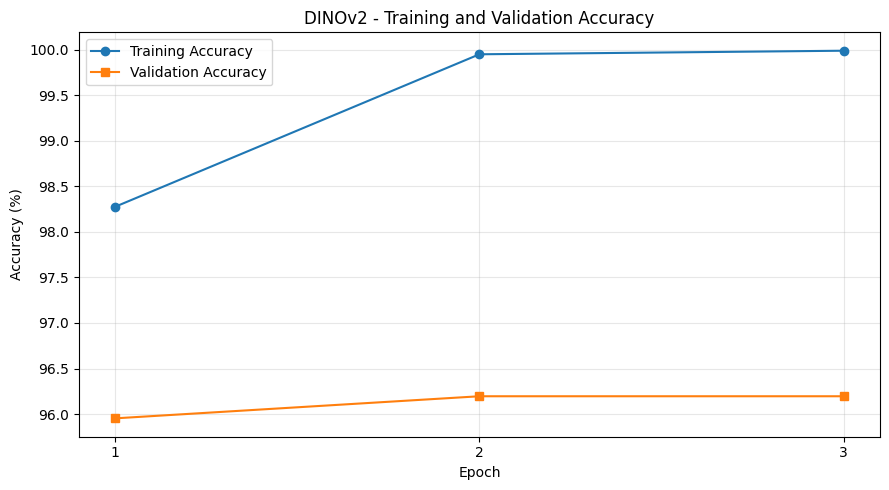

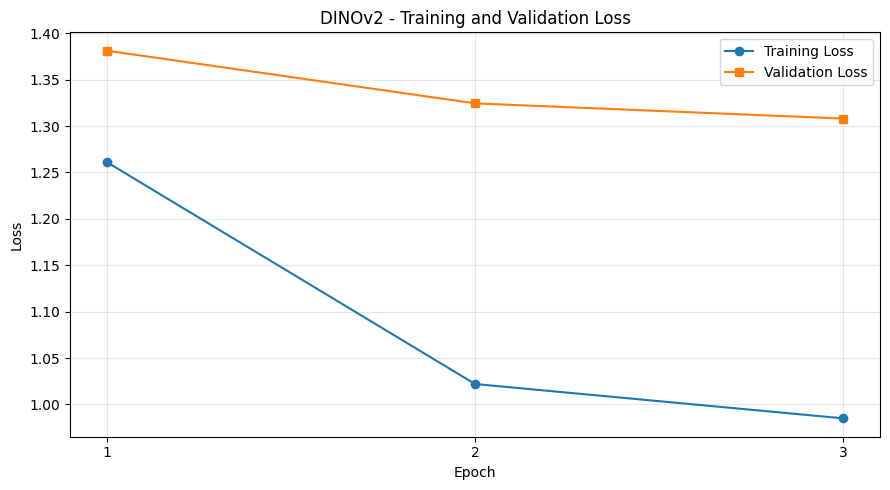

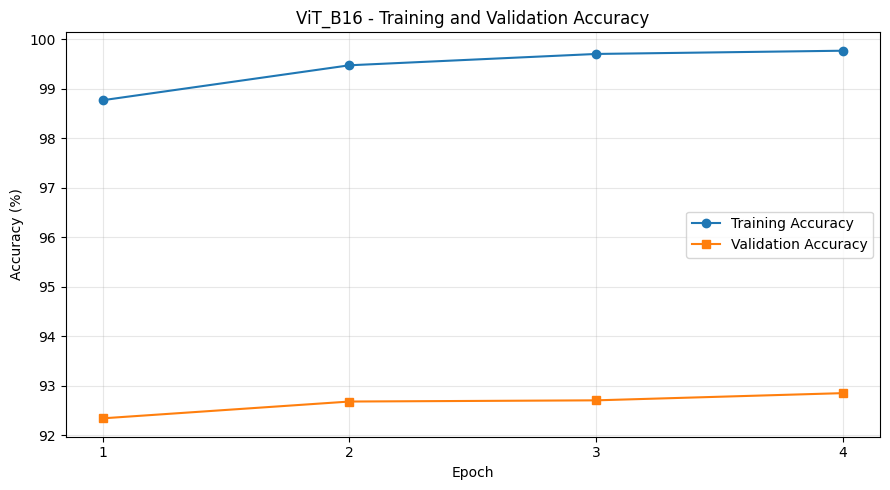

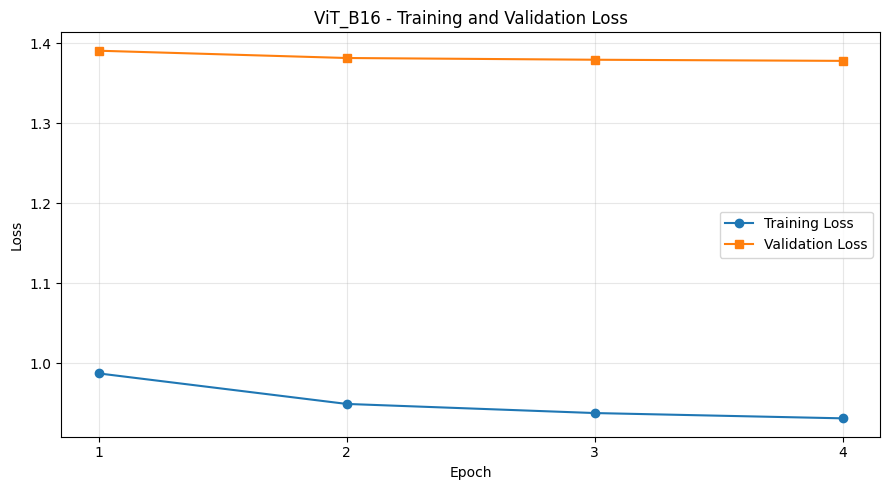

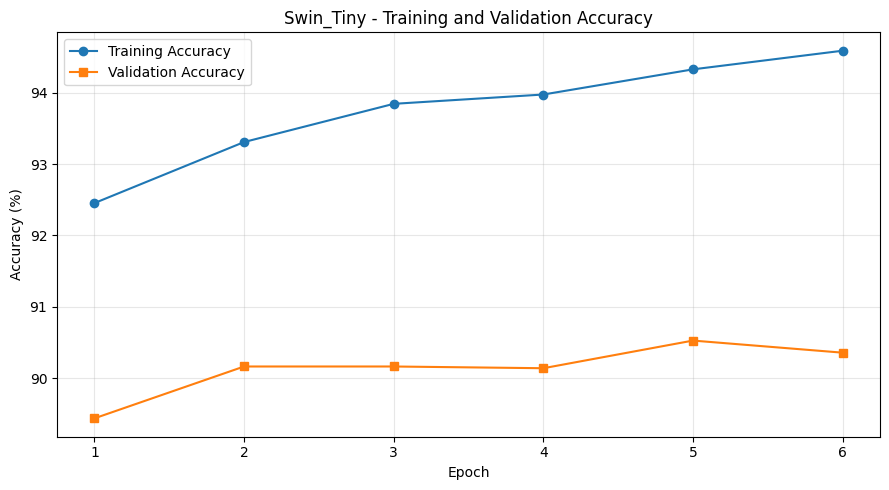

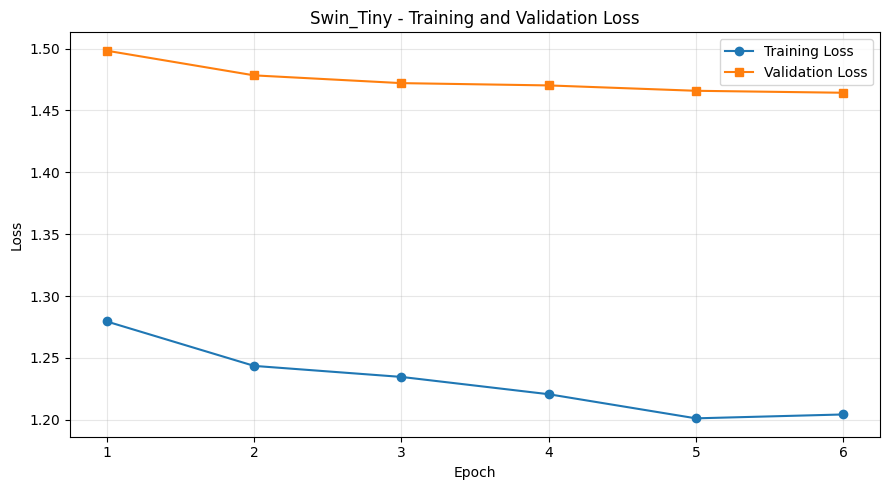

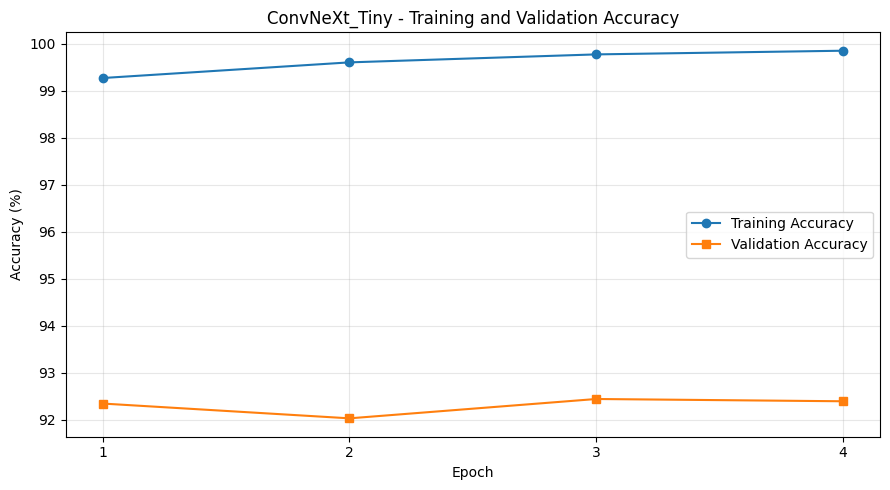

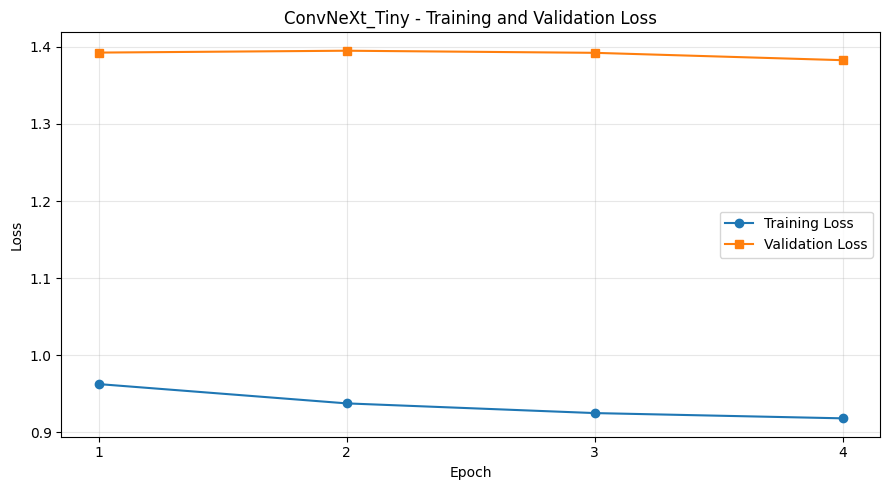

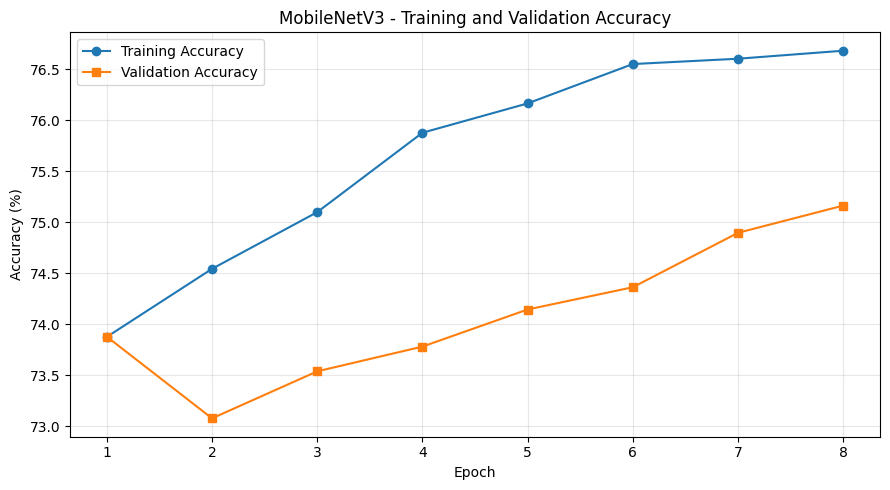

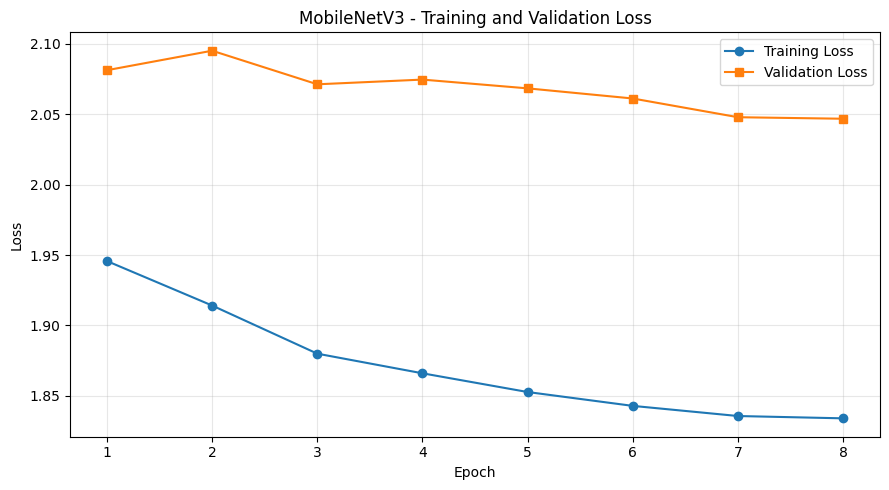

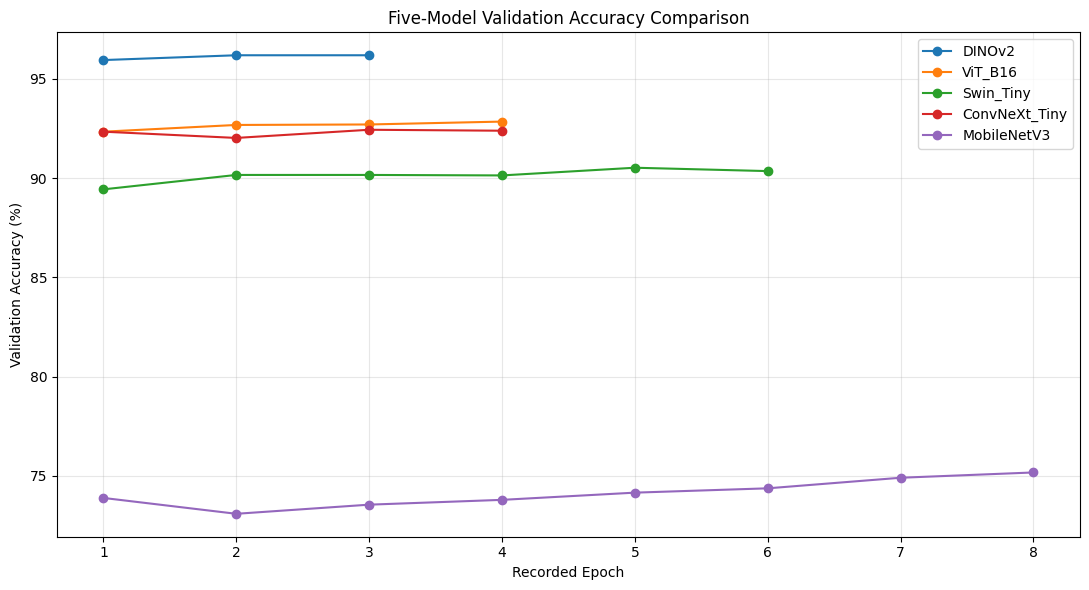

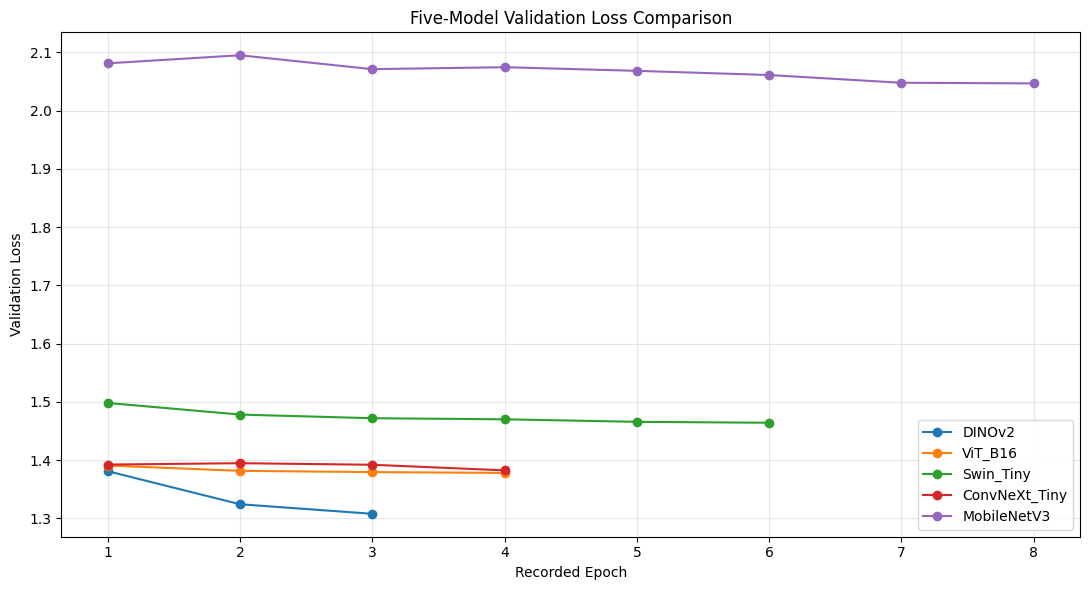


TRAINING HISTORY SUMMARY


,recorded_epochs,first_epoch,last_epoch,final_train_accuracy_percent,final_validation_accuracy_percent,final_train_loss,final_validation_loss,best_validation_accuracy_percent,best_validation_accuracy_epoch,best_validation_loss
DINOv2,3.0,1.0,3.0,99.986932,96.195784,0.985003,1.308073,96.195784,2.0,1.308073
ViT_B16,4.0,1.0,4.0,99.764783,92.851951,0.931454,1.378233,92.851951,4.0,1.378233
Swin_Tiny,6.0,1.0,6.0,94.590003,90.356191,1.204331,1.464335,90.525806,5.0,1.464335
ConvNeXt_Tiny,4.0,1.0,4.0,99.856256,92.391568,0.918246,1.382666,92.440029,3.0,1.382666
MobileNetV3,8.0,1.0,8.0,76.680823,75.163557,1.834077,2.046783,75.163557,8.0,2.046783


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

Uploaded: experiments/V2.1/Training_Curves/ConvNeXt_Tiny_accuracy_curve.png
Uploaded: experiments/V2.1/Training_Curves/ConvNeXt_Tiny_loss_curve.png


... (32 outputs left out)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

Uploaded: experiments/V2.1/Training_Curves/five_model_validation_loss.png

UPLOAD VERIFICATION
VERIFIED: experiments/V2.1/Training_Curves/ConvNeXt_Tiny_accuracy_curve.png
VERIFIED: experiments/V2.1/Training_Curves/ConvNeXt_Tiny_loss_curve.png
VERIFIED: experiments/V2.1/Training_Curves/DINOv2_accuracy_curve.png
VERIFIED: experiments/V2.1/Training_Curves/DINOv2_loss_curve.png
VERIFIED: experiments/V2.1/Training_Curves/MobileNetV3_accuracy_curve.png
VERIFIED: experiments/V2.1/Training_Curves/MobileNetV3_loss_curve.png
VERIFIED: experiments/V2.1/Training_Curves/Swin_Tiny_accuracy_curve.png
VERIFIED: experiments/V2.1/Training_Curves/Swin_Tiny_loss_curve.png
VERIFIED: experiments/V2.1/Training_Curves/ViT_B16_accuracy_curve.png
VERIFIED: experiments/V2.1/Training_Curves/ViT_B16_loss_curve.png
VERIFIED: experiments/V2.1/Training_Curves/five_model_training_history_summary.csv
VERIFIED: experiments/V2.1/Training_Curves/five_model_training_history_summary.json
VERIFIED: experiments/V2.1/Training_

In [10]:

# ============================================================
# CELL 4: TRAINING HISTORY VISUALIZATION + HF BACKUP
# ============================================================

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from huggingface_hub import HfApi, hf_hub_download
from kaggle_secrets import UserSecretsClient

# 1. Configuration
REPO_ID = "bandaruadarsh/FishVision-V2-Backup"
HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")

OUTPUT_DIR = Path("/kaggle/working/fishvision_training_curves")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

api = HfApi(token=HF_TOKEN)

history_files = {
    "DINOv2": "experiments/V2.1/DINOv2/training_history.csv",
    "ViT_B16": "experiments/V2.1/ViT_B16/training_history.csv",
    "Swin_Tiny": "experiments/V2.1/Swin_Tiny/training_history.csv",
    "ConvNeXt_Tiny": "experiments/V2.1/ConvNeXt_Tiny/training_history.csv",
    "MobileNetV3": "experiments/V2.1/MobileNetV3/training_history.csv"
}

# 2. Load histories using authenticated downloads
histories = {}

for model, filename in history_files.items():
    path = hf_hub_download(
        repo_id=REPO_ID,
        filename=filename,
        repo_type="model",
        token=HF_TOKEN
    )
    histories[model] = pd.read_csv(path)

print("Loaded histories:", list(histories.keys()))

# 3. Validate required columns
required_columns = [
    "epoch", "train_loss", "train_accuracy",
    "val_loss", "val_accuracy"
]

for model, df in histories.items():
    missing = [c for c in required_columns if c not in df.columns]
    if missing:
        raise ValueError(f"{model} is missing columns: {missing}")

# 4. Individual model plots
summary = {}

for model, df in histories.items():

    df = df.sort_values("epoch").copy()

    # Accuracy curve
    plt.figure(figsize=(9, 5))
    plt.plot(
        df["epoch"], df["train_accuracy"] * 100,
        marker="o", label="Training Accuracy"
    )
    plt.plot(
        df["epoch"], df["val_accuracy"] * 100,
        marker="s", label="Validation Accuracy"
    )
    plt.title(f"{model} - Training and Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.xticks(df["epoch"])
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    accuracy_path = OUTPUT_DIR / f"{model}_accuracy_curve.png"
    plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Loss curve
    plt.figure(figsize=(9, 5))
    plt.plot(
        df["epoch"], df["train_loss"],
        marker="o", label="Training Loss"
    )
    plt.plot(
        df["epoch"], df["val_loss"],
        marker="s", label="Validation Loss"
    )
    plt.title(f"{model} - Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(df["epoch"])
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    loss_path = OUTPUT_DIR / f"{model}_loss_curve.png"
    plt.savefig(loss_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    summary[model] = {
        "recorded_epochs": int(len(df)),
        "first_epoch": int(df["epoch"].min()),
        "last_epoch": int(df["epoch"].max()),
        "final_train_accuracy_percent": float(
            df.iloc[-1]["train_accuracy"] * 100
        ),
        "final_validation_accuracy_percent": float(
            df.iloc[-1]["val_accuracy"] * 100
        ),
        "final_train_loss": float(df.iloc[-1]["train_loss"]),
        "final_validation_loss": float(df.iloc[-1]["val_loss"]),
        "best_validation_accuracy_percent": float(
            df["val_accuracy"].max() * 100
        ),
        "best_validation_accuracy_epoch": int(
            df.loc[df["val_accuracy"].idxmax(), "epoch"]
        ),
        "best_validation_loss": float(df["val_loss"].min())
    }

# 5. Combined accuracy comparison
plt.figure(figsize=(11, 6))

for model, df in histories.items():
    plt.plot(
        df["epoch"],
        df["val_accuracy"] * 100,
        marker="o",
        label=model
    )

plt.title("Five-Model Validation Accuracy Comparison")
plt.xlabel("Recorded Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

combined_accuracy = OUTPUT_DIR / "five_model_validation_accuracy.png"
plt.savefig(combined_accuracy, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 6. Combined loss comparison
plt.figure(figsize=(11, 6))

for model, df in histories.items():
    plt.plot(
        df["epoch"],
        df["val_loss"],
        marker="o",
        label=model
    )

plt.title("Five-Model Validation Loss Comparison")
plt.xlabel("Recorded Epoch")
plt.ylabel("Validation Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

combined_loss = OUTPUT_DIR / "five_model_validation_loss.png"
plt.savefig(combined_loss, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 7. Save history summary
summary_path = OUTPUT_DIR / "five_model_training_history_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

summary_df = pd.DataFrame(summary).T
summary_csv = OUTPUT_DIR / "five_model_training_history_summary.csv"
summary_df.to_csv(summary_csv, index=True)

print("\nTRAINING HISTORY SUMMARY")
display(summary_df)

# 8. Upload all generated artifacts to Hugging Face
uploaded_files = []

for file_path in sorted(OUTPUT_DIR.iterdir()):
    if file_path.is_file():
        hf_path = (
            "experiments/V2.1/Training_Curves/"
            + file_path.name
        )

        api.upload_file(
            path_or_fileobj=str(file_path),
            path_in_repo=hf_path,
            repo_id=REPO_ID,
            repo_type="model",
            commit_message=f"Add training visualization: {file_path.name}"
        )

        uploaded_files.append(hf_path)
        print("Uploaded:", hf_path)

# 9. Verify remote files
remote_files = set(
    api.list_repo_files(
        repo_id=REPO_ID,
        repo_type="model"
    )
)

print("\nUPLOAD VERIFICATION")
verified = 0

for filename in uploaded_files:
    if filename in remote_files:
        print("VERIFIED:", filename)
        verified += 1
    else:
        print("NOT FOUND:", filename)

print("\n" + "=" * 65)
print("CELL 4 COMPLETED")
print("Generated artifacts:", len(uploaded_files))
print("Verified on Hugging Face:", verified)
print("Output directory:", OUTPUT_DIR)
print("=" * 65)

assert verified == len(uploaded_files), "Some files were not verified!"


# Cell 5 — Dataset Integrity & Duplicate Audit

In [11]:

# ================================================================
# CELL 5: FISHVISION DATASET INTEGRITY & DUPLICATE AUDIT
# Read-only audit | SHA-256 | Perceptual Hash | HF Backup
# ================================================================

import os
import json
import time
import hashlib
import itertools
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image
from scipy.fftpack import dct
from huggingface_hub import HfApi
from kaggle_secrets import UserSecretsClient

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

DATASET_ROOT = Path(
    "/kaggle/input/datasets/adarshbandaru/fishvision-152-classes"
)

SPLITS = ["train", "val", "test"]
EXPECTED_CLASSES = 152

OUTPUT_DIR = Path("/kaggle/working/fishvision_integrity_audit")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REPO_ID = "bandaruadarsh/FishVision-V2-Backup"
HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")

# pHash Hamming distance threshold.
# <= 6 means visually similar candidate, not confirmed duplicate.
PHASH_THRESHOLD = 6

# ------------------------------------------------
# 2. VERIFY DATASET
# ------------------------------------------------

for split in SPLITS:
    split_path = DATASET_ROOT / split
    assert split_path.is_dir(), f"Missing split: {split_path}"

print("Dataset:", DATASET_ROOT)

# ------------------------------------------------
# 3. COLLECT IMAGE PATHS AND CLASS COUNTS
# ------------------------------------------------

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

records = []
class_sets = {}

for split in SPLITS:
    split_dir = DATASET_ROOT / split
    class_dirs = sorted(
        p for p in split_dir.iterdir() if p.is_dir()
    )

    class_sets[split] = {p.name for p in class_dirs}

    for class_dir in class_dirs:
        image_files = sorted(
            p for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        for image_path in image_files:
            records.append({
                "split": split,
                "class_name": class_dir.name,
                "image_path": str(image_path),
                "relative_path": str(image_path.relative_to(DATASET_ROOT))
            })

images_df = pd.DataFrame(records)

if images_df.empty:
    raise RuntimeError("No images found in dataset.")

all_classes = sorted(set.union(*class_sets.values()))

print("\nIMAGE COUNTS")
print(images_df.groupby("split").size().to_string())

print("\nCLASS COUNTS")
for split in SPLITS:
    print(f"{split}: {len(class_sets[split])} classes")

print("Union of classes:", len(all_classes))

if len(all_classes) != EXPECTED_CLASSES:
    print(
        f"WARNING: Expected {EXPECTED_CLASSES} classes, "
        f"but found {len(all_classes)}."
    )

# ------------------------------------------------
# 4. PER-CLASS DISTRIBUTION
# ------------------------------------------------

distribution = (
    images_df.groupby(["class_name", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=all_classes, columns=SPLITS, fill_value=0)
)

distribution["total"] = distribution[SPLITS].sum(axis=1)

distribution.to_csv(
    OUTPUT_DIR / "class_distribution_152_classes.csv"
)

missing_class_records = []

for split in SPLITS:
    missing = sorted(set(all_classes) - class_sets[split])

    for class_name in missing:
        missing_class_records.append({
            "split": split,
            "missing_class": class_name
        })

missing_df = pd.DataFrame(
    missing_class_records,
    columns=["split", "missing_class"]
)

missing_df.to_csv(
    OUTPUT_DIR / "missing_classes_by_split.csv",
    index=False
)

print("\nMISSING CLASSES")
if missing_df.empty:
    print("None")
else:
    print(missing_df.to_string(index=False))

# ------------------------------------------------
# 5. SHA-256 EXACT DUPLICATE AUDIT
# ------------------------------------------------

def calculate_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


sha_records = []
unreadable = []

print("\nCalculating SHA-256 hashes...")

for index, row in images_df.iterrows():
    try:
        sha = calculate_sha256(row["image_path"])

        sha_records.append({
            "split": row["split"],
            "class_name": row["class_name"],
            "relative_path": row["relative_path"],
            "sha256": sha
        })

    except Exception as e:
        unreadable.append({
            "relative_path": row["relative_path"],
            "error": str(e)
        })

    if (index + 1) % 2000 == 0:
        print(f"Processed {index + 1}/{len(images_df)} images")

sha_df = pd.DataFrame(sha_records)

sha_df.to_csv(
    OUTPUT_DIR / "sha256_image_hashes.csv",
    index=False
)

unreadable_df = pd.DataFrame(
    unreadable,
    columns=["relative_path", "error"]
)

unreadable_df.to_csv(
    OUTPUT_DIR / "unreadable_images.csv",
    index=False
)

# All exact duplicate groups, including within-split duplicates
duplicate_groups = []

for sha, group in sha_df.groupby("sha256"):
    if len(group) > 1:
        duplicate_groups.append({
            "sha256": sha,
            "duplicate_count": len(group),
            "splits": ", ".join(sorted(group["split"].unique())),
            "paths": " | ".join(group["relative_path"].tolist())
        })

exact_duplicates_df = pd.DataFrame(
    duplicate_groups,
    columns=["sha256", "duplicate_count", "splits", "paths"]
)

exact_duplicates_df.to_csv(
    OUTPUT_DIR / "exact_duplicate_groups.csv",
    index=False
)

# Cross-split exact duplicate groups
cross_split_exact = exact_duplicates_df[
    exact_duplicates_df["splits"].apply(
        lambda x: len(x.split(", ")) > 1
    )
].copy()

cross_split_exact.to_csv(
    OUTPUT_DIR / "cross_split_exact_duplicates.csv",
    index=False
)

print("\nEXACT DUPLICATE AUDIT")
print("Unique SHA-256 values:", sha_df["sha256"].nunique())
print("Duplicate groups:", len(exact_duplicates_df))
print("Cross-split duplicate groups:", len(cross_split_exact))
print("Unreadable images:", len(unreadable_df))

# ------------------------------------------------
# 6. PERCEPTUAL HASH FUNCTION (pHash)
# ------------------------------------------------

def calculate_phash(path):
    """
    64-bit perceptual hash using 2D DCT.
    Returns a 64-character binary string.
    """

    with Image.open(path) as img:
        img = img.convert("L").resize((32, 32))
        pixels = np.asarray(img, dtype=np.float32)

    dct_result = dct(
        dct(pixels, axis=0, norm="ortho"),
        axis=1,
        norm="ortho"
    )

    low_frequency = dct_result[:8, :8]
    median_value = np.median(low_frequency.flatten()[1:])

    bits = low_frequency > median_value

    return "".join("1" if b else "0" for b in bits.flatten())


# ------------------------------------------------
# 7. CALCULATE PERCEPTUAL HASHES
# ------------------------------------------------

print("\nCalculating perceptual hashes...")

phash_records = []

for index, row in images_df.iterrows():
    try:
        phash = calculate_phash(row["image_path"])

        phash_records.append({
            "split": row["split"],
            "class_name": row["class_name"],
            "relative_path": row["relative_path"],
            "phash": phash
        })

    except Exception as e:
        # Image may already have been listed as unreadable.
        continue

    if (index + 1) % 2000 == 0:
        print(f"Processed {index + 1}/{len(images_df)} images")

phash_df = pd.DataFrame(phash_records)

phash_df.to_csv(
    OUTPUT_DIR / "perceptual_hashes.csv",
    index=False
)

# ------------------------------------------------
# 8. CROSS-SPLIT NEAR-DUPLICATE SEARCH
# ------------------------------------------------

# Convert binary pHash strings into uint8 arrays.
def binary_hash_to_bytes(hash_string):
    return np.packbits(
        np.fromiter(
            (int(bit) for bit in hash_string),
            dtype=np.uint8
        )
    )


phash_df["hash_bytes"] = phash_df["phash"].apply(
    binary_hash_to_bytes
)

# Lookup table for fast byte-level population counts.
POPCOUNT = np.array(
    [bin(i).count("1") for i in range(256)],
    dtype=np.uint8
)


def compare_hash_sets(df_a, df_b, split_a, split_b):
    """
    Compare two different splits in chunks.
    Only cross-split near-duplicate candidates are reported.
    """

    if df_a.empty or df_b.empty:
        return []

    hashes_a = np.stack(df_a["hash_bytes"].values)
    hashes_b = np.stack(df_b["hash_bytes"].values)

    results = []
    chunk_size = 128

    for start in range(0, len(hashes_a), chunk_size):
        end = min(start + chunk_size, len(hashes_a))

        chunk = hashes_a[start:end]

        xor_values = np.bitwise_xor(
            chunk[:, None, :],
            hashes_b[None, :, :]
        )

        distances = POPCOUNT[xor_values].sum(axis=2)

        matches = np.argwhere(
            (distances <= PHASH_THRESHOLD) &
            (distances > 0)
        )

        for local_i, j in matches:
            i = start + local_i
            distance = int(distances[local_i, j])

            results.append({
                "split_a": split_a,
                "split_b": split_b,
                "class_a": df_a.iloc[i]["class_name"],
                "class_b": df_b.iloc[j]["class_name"],
                "path_a": df_a.iloc[i]["relative_path"],
                "path_b": df_b.iloc[j]["relative_path"],
                "phash_hamming_distance": distance
            })

        if end % 1024 == 0 or end == len(hashes_a):
            print(
                f"Compared {split_a} vs {split_b}: "
                f"{end}/{len(hashes_a)}"
            )

    return results


near_duplicate_records = []

for split_a, split_b in itertools.combinations(SPLITS, 2):

    df_a = phash_df[phash_df["split"] == split_a].reset_index(drop=True)
    df_b = phash_df[phash_df["split"] == split_b].reset_index(drop=True)

    print(f"\nNear-duplicate search: {split_a} vs {split_b}")

    near_duplicate_records.extend(
        compare_hash_sets(df_a, df_b, split_a, split_b)
    )


near_duplicates_df = pd.DataFrame(
    near_duplicate_records,
    columns=[
        "split_a", "split_b",
        "class_a", "class_b",
        "path_a", "path_b",
        "phash_hamming_distance"
    ]
)

if not near_duplicates_df.empty:
    near_duplicates_df = near_duplicates_df.sort_values(
        "phash_hamming_distance"
    )

near_duplicates_df.to_csv(
    OUTPUT_DIR / "cross_split_near_duplicate_candidates.csv",
    index=False
)

print("\nNEAR-DUPLICATE CANDIDATES")
print("Candidate pairs:", len(near_duplicates_df))
print("Hamming threshold:", PHASH_THRESHOLD)

# ------------------------------------------------
# 9. CREATE AUDIT SUMMARY
# ------------------------------------------------

split_counts = {
    split: int((images_df["split"] == split).sum())
    for split in SPLITS
}

class_counts = {
    split: int(len(class_sets[split]))
    for split in SPLITS
}

summary = {
    "dataset_root": str(DATASET_ROOT),
    "expected_classes": EXPECTED_CLASSES,
    "observed_class_union": len(all_classes),
    "split_image_counts": split_counts,
    "split_class_counts": class_counts,
    "total_images_found": int(len(images_df)),
    "total_images_sha256_processed": int(len(sha_df)),
    "unique_sha256_hashes": int(sha_df["sha256"].nunique()),
    "exact_duplicate_groups": int(len(exact_duplicates_df)),
    "cross_split_exact_duplicate_groups": int(len(cross_split_exact)),
    "near_duplicate_candidate_pairs": int(len(near_duplicates_df)),
    "phash_hamming_threshold": PHASH_THRESHOLD,
    "unreadable_images": int(len(unreadable_df)),
    "missing_classes": {
        split: sorted(set(all_classes) - class_sets[split])
        for split in SPLITS
    },
    "notes": [
        "Exact duplicates are identified using SHA-256.",
        "Near-duplicate candidates are identified using 64-bit DCT perceptual hashes.",
        "Near-duplicate candidates require manual visual review.",
        "This audit does not modify the source dataset."
    ]
}

summary_path = OUTPUT_DIR / "dataset_integrity_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

# Create readable text report
report_path = OUTPUT_DIR / "dataset_integrity_report.txt"

with open(report_path, "w") as f:
    f.write("FISHVISION DATASET INTEGRITY AUDIT\n")
    f.write("=" * 65 + "\n\n")

    f.write(f"Dataset: {DATASET_ROOT}\n")
    f.write(f"Total images: {len(images_df)}\n")
    f.write(f"Class union: {len(all_classes)}\n\n")

    for split in SPLITS:
        f.write(
            f"{split}: {split_counts[split]} images, "
            f"{class_counts[split]} classes\n"
        )

    f.write("\nEXACT DUPLICATE AUDIT\n")
    f.write(f"Duplicate groups: {len(exact_duplicates_df)}\n")
    f.write(f"Cross-split groups: {len(cross_split_exact)}\n")

    f.write("\nNEAR-DUPLICATE AUDIT\n")
    f.write(f"Candidate pairs: {len(near_duplicates_df)}\n")
    f.write(f"pHash threshold: {PHASH_THRESHOLD}\n")

    f.write("\nUNREADABLE IMAGES\n")
    f.write(f"Count: {len(unreadable_df)}\n")

# ------------------------------------------------
# 10. SAVE CLASS DISTRIBUTION SUMMARY
# ------------------------------------------------

print("\nCLASS DISTRIBUTION SAMPLE")
display(distribution.head(15))

print("\nDATASET INTEGRITY SUMMARY")
print(json.dumps(summary, indent=2))

# ------------------------------------------------
# 11. UPLOAD AUDIT ARTIFACTS TO HF
# ------------------------------------------------

api = HfApi(token=HF_TOKEN)

uploaded_files = []

for file_path in sorted(OUTPUT_DIR.iterdir()):
    if not file_path.is_file():
        continue

    hf_path = (
        "experiments/V2.1/Dataset_Integrity_Audit/"
        + file_path.name
    )

    api.upload_file(
        path_or_fileobj=str(file_path),
        path_in_repo=hf_path,
        repo_id=REPO_ID,
        repo_type="model",
        commit_message=f"Add dataset integrity audit: {file_path.name}"
    )

    uploaded_files.append(hf_path)
    print("Uploaded:", hf_path)

# ------------------------------------------------
# 12. VERIFY REMOTE UPLOADS
# ------------------------------------------------

remote_files = set(
    api.list_repo_files(
        repo_id=REPO_ID,
        repo_type="model"
    )
)

verified = 0

print("\nREMOTE VERIFICATION")

for filename in uploaded_files:
    if filename in remote_files:
        print("VERIFIED:", filename)
        verified += 1
    else:
        print("NOT FOUND:", filename)

print("\n" + "=" * 65)
print("DATASET INTEGRITY AUDIT COMPLETED")
print("Images scanned:", len(images_df))
print("SHA-256 records:", len(sha_df))
print("Exact duplicate groups:", len(exact_duplicates_df))
print("Cross-split exact duplicate groups:", len(cross_split_exact))
print("Near-duplicate candidates:", len(near_duplicates_df))
print("Unreadable images:", len(unreadable_df))
print("Artifacts generated:", len(uploaded_files))
print("Artifacts verified:", verified)
print("Local output:", OUTPUT_DIR)
print("=" * 65)

assert verified == len(uploaded_files), (
    "Some audit artifacts were not verified on Hugging Face."
)


Dataset: /kaggle/input/datasets/adarshbandaru/fishvision-152-classes

IMAGE COUNTS
split
test      3309
train    15304
val       4127

CLASS COUNTS
train: 152 classes
val: 151 classes
test: 152 classes
Union of classes: 152

MISSING CLASSES
split   missing_class
  val aesopia_cornuta

Calculating SHA-256 hashes...
Processed 2000/22740 images
Processed 4000/22740 images
Processed 6000/22740 images
Processed 8000/22740 images
Processed 10000/22740 images
Processed 12000/22740 images
Processed 14000/22740 images
Processed 16000/22740 images
Processed 18000/22740 images
Processed 20000/22740 images
Processed 22000/22740 images

EXACT DUPLICATE AUDIT
Unique SHA-256 values: 18657
Duplicate groups: 3733
Cross-split duplicate groups: 3645
Unreadable images: 0

Calculating perceptual hashes...
Processed 2000/22740 images
Processed 4000/22740 images
Processed 6000/22740 images
Processed 8000/22740 images
Processed 10000/22740 images
Processed 12000/22740 images
Processed 14000/22740 images
Proce

split,train,val,test,total
class_name,,,,
A73EGS-P,3,1,2,6
Bangus,171,52,34,257
Big Head Carp,201,63,43,307
Black Spotted Barb,200,63,40,303
Catfish,314,97,62,473
Climbing Perch,151,48,30,229
Fourfinger Threadfin,191,60,38,289
Freshwater Eel,271,84,55,410
Glass Perchlet,397,124,77,598



DATASET INTEGRITY SUMMARY
{
  "dataset_root": "/kaggle/input/datasets/adarshbandaru/fishvision-152-classes",
  "expected_classes": 152,
  "observed_class_union": 152,
  "split_image_counts": {
    "train": 15304,
    "val": 4127,
    "test": 3309
  },
  "split_class_counts": {
    "train": 152,
    "val": 151,
    "test": 152
  },
  "total_images_found": 22740,
  "total_images_sha256_processed": 22740,
  "unique_sha256_hashes": 18657,
  "exact_duplicate_groups": 3733,
  "cross_split_exact_duplicate_groups": 3645,
  "near_duplicate_candidate_pairs": 23780,
  "phash_hamming_threshold": 6,
  "unreadable_images": 0,
  "missing_classes": {
    "train": [],
    "val": [
      "aesopia_cornuta"
    ],
    "test": []
  },
  "notes": [
    "Exact duplicates are identified using SHA-256.",
    "Near-duplicate candidates are identified using 64-bit DCT perceptual hashes.",
    "Near-duplicate candidates require manual visual review.",
    "This audit does not modify the source dataset."
  ]
}
Up

#Cell 6 — Exact duplicate impact analysis

In [12]:

# ============================================================
# CELL 6: EXACT DUPLICATE IMPACT ANALYSIS
# ============================================================

import pandas as pd
import json
from pathlib import Path
from collections import Counter

AUDIT_DIR = Path("/kaggle/working/fishvision_integrity_audit")

sha_path = AUDIT_DIR / "sha256_image_hashes.csv"

df = pd.read_csv(sha_path)

print("Loaded SHA records:", len(df))
print("Columns:", df.columns.tolist())

# ------------------------------------------------
# 1. Identify cross-split duplicate groups
# ------------------------------------------------

duplicate_groups = []

for sha, group in df.groupby("sha256"):

    if group["split"].nunique() <= 1:
        continue

    splits = sorted(group["split"].unique())

    duplicate_groups.append({
        "sha256": sha,
        "group_size": len(group),
        "splits": splits,
        "classes": sorted(group["class_name"].unique()),
        "paths": group["relative_path"].tolist(),
        "class_mismatch": group["class_name"].nunique() > 1
    })

groups_df = pd.DataFrame(duplicate_groups)

print("\nCross-split exact duplicate groups:", len(groups_df))

# ------------------------------------------------
# 2. Count groups by split combination
# ------------------------------------------------

pair_counts = Counter()

for splits in groups_df["splits"]:
    for i in range(len(splits)):
        for j in range(i + 1, len(splits)):
            pair_counts[(splits[i], splits[j])] += 1

print("\nDUPLICATE GROUPS BY SPLIT PAIR")

for pair, count in sorted(pair_counts.items()):
    print(f"{pair[0]} vs {pair[1]}: {count}")

# ------------------------------------------------
# 3. Count affected unique images per split
# ------------------------------------------------

affected_paths = {
    "train": set(),
    "val": set(),
    "test": set()
}

for _, group in groups_df.iterrows():

    for path in group["paths"]:
        split = path.split("/")[0]

        if split in affected_paths:
            affected_paths[split].add(path)

print("\nAFFECTED UNIQUE IMAGE FILES")

for split, paths in affected_paths.items():
    print(f"{split}: {len(paths)}")

# ------------------------------------------------
# 4. Detect cross-class duplicate groups
# ------------------------------------------------

cross_class_groups = groups_df[
    groups_df["class_mismatch"]
].copy()

print("\nCROSS-CLASS DUPLICATE GROUPS:",
      len(cross_class_groups))

# ------------------------------------------------
# 5. Save detailed group report
# ------------------------------------------------

groups_df["splits"] = groups_df["splits"].apply(
    lambda x: ", ".join(x)
)

groups_df["classes"] = groups_df["classes"].apply(
    lambda x: ", ".join(x)
)

groups_df["paths"] = groups_df["paths"].apply(
    lambda x: " | ".join(x)
)

groups_df.to_csv(
    AUDIT_DIR / "cross_split_duplicate_impact.csv",
    index=False
)

cross_class_groups.to_csv(
    AUDIT_DIR / "cross_class_duplicate_groups.csv",
    index=False
)

impact = {
    "cross_split_duplicate_groups": int(len(groups_df)),
    "duplicate_groups_by_split_pair": {
        f"{a}_vs_{b}": int(count)
        for (a, b), count in pair_counts.items()
    },
    "affected_unique_images_by_split": {
        split: len(paths)
        for split, paths in affected_paths.items()
    },
    "cross_class_duplicate_groups": int(len(cross_class_groups))
}

with open(
    AUDIT_DIR / "duplicate_impact_summary.json", "w"
) as f:
    json.dump(impact, f, indent=4)

print("\nFINAL DUPLICATE IMPACT SUMMARY")
print(json.dumps(impact, indent=4))

print("\nSaved reports:")
print("cross_split_duplicate_impact.csv")
print("cross_class_duplicate_groups.csv")
print("duplicate_impact_summary.json")


Loaded SHA records: 22740
Columns: ['split', 'class_name', 'relative_path', 'sha256']

Cross-split exact duplicate groups: 3645

DUPLICATE GROUPS BY SPLIT PAIR
test vs train: 1242
test vs val: 301
train vs val: 2192

AFFECTED UNIQUE IMAGE FILES
train: 3627
val: 2486
test: 1512

CROSS-CLASS DUPLICATE GROUPS: 0

FINAL DUPLICATE IMPACT SUMMARY
{
    "cross_split_duplicate_groups": 3645,
    "duplicate_groups_by_split_pair": {
        "train_vs_val": 2192,
        "test_vs_val": 301,
        "test_vs_train": 1242
    },
    "affected_unique_images_by_split": {
        "train": 3627,
        "val": 2486,
        "test": 1512
    },
    "cross_class_duplicate_groups": 0
}

Saved reports:
cross_split_duplicate_impact.csv
cross_class_duplicate_groups.csv
duplicate_impact_summary.json


In [13]:

import pandas as pd
from pathlib import Path

AUDIT_DIR = Path("/kaggle/working/fishvision_integrity_audit")

df = pd.read_csv(AUDIT_DIR / "sha256_image_hashes.csv")

# Count unique image contents per class
unique_images = df.drop_duplicates(
    subset=["class_name", "sha256"]
)

class_summary = (
    unique_images.groupby("class_name")
    .agg(
        unique_images=("sha256", "nunique"),
        original_files=("relative_path", "count")
    )
    .sort_values("unique_images")
    .reset_index()
)

print("Total classes:", len(class_summary))
print("\nLOWEST UNIQUE IMAGE COUNTS")
display(class_summary.head(30))

print("\nCLASS COUNT DISTRIBUTION")
print(class_summary["unique_images"].describe())

print("\nClasses with fewer than 3 unique images:",
      (class_summary["unique_images"] < 3).sum())

print("Classes with fewer than 10 unique images:",
      (class_summary["unique_images"] < 10).sum())

class_summary.to_csv(
    AUDIT_DIR / "unique_images_per_class.csv",
    index=False
)


Total classes: 152

LOWEST UNIQUE IMAGE COUNTS


,class_name,unique_images,original_files
0,aesopia_cornuta,2,2
1,acanthaluteres_spilomelanurus,3,3
2,acanthaluteres_brownii,4,4
3,anampses_femininus,4,4
4,alectis_indica,4,4
5,achoerodus_gouldii,4,4
6,alectis_ciliaris,4,4
7,acreichthys_tomentosus,5,5
8,anampses_neoguinaicus,5,5
9,A73EGS-P,6,6



CLASS COUNT DISTRIBUTION
count    152.000000
mean     122.743421
std      104.873907
min        2.000000
25%       54.500000
50%      121.500000
75%      159.000000
max      784.000000
Name: unique_images, dtype: float64

Classes with fewer than 3 unique images: 1
Classes with fewer than 10 unique images: 20


# Cell 1 — Calculate image requirements and verify scientific names

In [14]:

# ============================================================
# FISHVISION V2.2 - CELL 1
# CLASS REQUIREMENTS + TAXONOMY MATCHING
# ============================================================

import requests
import pandas as pd
import time
from pathlib import Path
from urllib.parse import quote

AUDIT_DIR = Path("/kaggle/working/fishvision_integrity_audit")
OUTPUT_DIR = Path("/kaggle/working/FishVision_V2_2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_IMAGES = 40

# Load unique image counts from the SHA-256 audit
counts_path = AUDIT_DIR / "unique_images_per_class.csv"

if not counts_path.exists():
    raise FileNotFoundError(
        "Run the unique-images-per-class analysis first."
    )

classes = pd.read_csv(counts_path)

required_columns = {"class_name", "unique_images"}
assert required_columns.issubset(classes.columns)

classes["additional_needed"] = (
    TARGET_IMAGES - classes["unique_images"]
).clip(lower=0)

classes["normalized_query"] = (
    classes["class_name"]
    .astype(str)
    .str.replace("_", " ", regex=False)
    .str.strip()
)

print("Total classes:", len(classes))
print("Classes needing additional images:",
      int((classes["additional_needed"] > 0).sum()))
print("Total additional images required:",
      int(classes["additional_needed"].sum()))

# API configuration
session = requests.Session()
session.headers.update({
    "User-Agent": "FishVisionV2.2-DatasetResearch/1.0 (academic research)"
})

def get_json(url, params=None):
    response = session.get(
        url,
        params=params,
        timeout=30
    )
    response.raise_for_status()
    return response.json()

taxonomy_records = []

for index, row in classes.iterrows():

    class_name = row["class_name"]
    query = row["normalized_query"]

    print(
        f"[{index + 1}/{len(classes)}] "
        f"Checking: {class_name}"
    )

    record = {
        "class_name": class_name,
        "existing_unique_images": int(row["unique_images"]),
        "additional_needed": int(row["additional_needed"]),
        "search_query": query,
        "gbif_scientific_name": "",
        "gbif_taxon_key": "",
        "gbif_rank": "",
        "gbif_status": "",
        "gbif_confidence": "",
        "inat_taxon_id": "",
        "inat_scientific_name": "",
        "inat_common_name": "",
        "inat_rank": "",
        "manual_scientific_name": "",
        "approved": ""
    }

    # GBIF taxonomy match
    try:
        gbif = get_json(
            "https://api.gbif.org/v1/species/match",
            params={
                "name": query,
                "strict": "true"
            }
        )

        if gbif.get("matchType") not in [None, "NONE"]:
            record.update({
                "gbif_scientific_name": gbif.get(
                    "scientificName", ""
                ),
                "gbif_taxon_key": gbif.get("speciesKey") or gbif.get(
                    "usageKey", ""
                ),
                "gbif_rank": gbif.get("rank", ""),
                "gbif_status": gbif.get("status", ""),
                "gbif_confidence": gbif.get("confidence", "")
            })

    except Exception as e:
        print("  GBIF lookup warning:", str(e)[:150])

    # iNaturalist taxonomy match
    try:
        inat = get_json(
            "https://api.inaturalist.org/v1/taxa/autocomplete",
            params={
                "q": query,
                "per_page": 5
            }
        )

        results = inat.get("results", [])

        if results:
            # Save candidate, not automatic approval.
            candidate = results[0]

            record.update({
                "inat_taxon_id": candidate.get("id", ""),
                "inat_scientific_name": candidate.get("name", ""),
                "inat_common_name": candidate.get(
                    "preferred_common_name", ""
                ),
                "inat_rank": candidate.get("rank", "")
            })

    except Exception as e:
        print("  iNaturalist lookup warning:", str(e)[:150])

    taxonomy_records.append(record)

    time.sleep(0.35)

taxonomy_df = pd.DataFrame(taxonomy_records)

taxonomy_path = OUTPUT_DIR / "v2_2_taxonomy_review.csv"
taxonomy_df.to_csv(taxonomy_path, index=False)

requirements_path = OUTPUT_DIR / "v2_2_image_requirements.csv"

classes.to_csv(requirements_path, index=False)

print("\nTAXONOMY MATCHING COMPLETED")
print("Classes:", len(taxonomy_df))
print("GBIF matches:",
      int(taxonomy_df["gbif_taxon_key"].ne("").sum()))
print("iNaturalist matches:",
      int(taxonomy_df["inat_taxon_id"].ne("").sum()))

print("\nCLASSES NEEDING THE MOST ADDITIONAL IMAGES")
display(
    classes.sort_values(
        "additional_needed",
        ascending=False
    ).head(25)
)

print("\nTAXONOMY REVIEW SAMPLE")
display(taxonomy_df.head(25))

print("\nSaved:")
print(taxonomy_path)
print(requirements_path)


Total classes: 152
Classes needing additional images: 32
Total additional images required: 951
[1/152] Checking: aesopia_cornuta
[2/152] Checking: acanthaluteres_spilomelanurus
[3/152] Checking: acanthaluteres_brownii
[4/152] Checking: anampses_femininus
[5/152] Checking: alectis_indica
[6/152] Checking: achoerodus_gouldii
[7/152] Checking: alectis_ciliaris
[8/152] Checking: acreichthys_tomentosus
[9/152] Checking: anampses_neoguinaicus
[10/152] Checking: A73EGS-P
[11/152] Checking: anampses_lennardi
[12/152] Checking: alepes_kleinii
[13/152] Checking: acanthopagrus_australis
[14/152] Checking: anampses_melanurus
[15/152] Checking: anampses_geographicus
[16/152] Checking: anampses_elegans
[17/152] Checking: achoerodus_viridis
[18/152] Checking: anampses_twistii
[19/152] Checking: acanthaluteres_vittiger
[20/152] Checking: acanthistius_cinctus
[21/152] Checking: acanthopagrus_berda
[22/152] Checking: aluterus_monoceros
[23/152] Checking: stomatorhinus ivindoensis
[24/152] Checking: aeth

,class_name,unique_images,original_files,additional_needed,normalized_query
0,aesopia_cornuta,2,2,38,aesopia cornuta
1,acanthaluteres_spilomelanurus,3,3,37,acanthaluteres spilomelanurus
2,acanthaluteres_brownii,4,4,36,acanthaluteres brownii
3,anampses_femininus,4,4,36,anampses femininus
4,alectis_indica,4,4,36,alectis indica
5,achoerodus_gouldii,4,4,36,achoerodus gouldii
6,alectis_ciliaris,4,4,36,alectis ciliaris
7,acreichthys_tomentosus,5,5,35,acreichthys tomentosus
8,anampses_neoguinaicus,5,5,35,anampses neoguinaicus
9,A73EGS-P,6,6,34,A73EGS-P



TAXONOMY REVIEW SAMPLE


,class_name,existing_unique_images,additional_needed,search_query,gbif_scientific_name,gbif_taxon_key,gbif_rank,gbif_status,gbif_confidence,inat_taxon_id,inat_scientific_name,inat_common_name,inat_rank,manual_scientific_name,approved
0,aesopia_cornuta,2,38,aesopia cornuta,"Aesopia cornuta Kaup, 1858",2410248,SPECIES,ACCEPTED,99,530857,Aesopia cornuta,Thickray Sole,species,,
1,acanthaluteres_spilomelanurus,3,37,acanthaluteres spilomelanurus,"Acanthaluteres spilomelanurus (Quoy & Gaimard,...",2406696,SPECIES,ACCEPTED,99,353497,Acanthaluteres spilomelanurus,Bridled Leatherjacket,species,,
2,acanthaluteres_brownii,4,36,acanthaluteres brownii,"Acanthaluteres brownii (Richardson, 1846)",2406699,SPECIES,ACCEPTED,99,530366,Acanthaluteres brownii,Spinytail Leatherjacket,species,,
3,anampses_femininus,4,36,anampses femininus,"Anampses femininus Randall, 1972",2383485,SPECIES,ACCEPTED,99,94020,Anampses femininus,Bluetail Wrasse,species,,
4,alectis_indica,4,36,alectis indica,"Alectis indica (Rüppell, 1830)",9817213,SPECIES,ACCEPTED,98,1360118,Scyris indica,Diamond Trevally,species,,
5,achoerodus_gouldii,4,36,achoerodus gouldii,"Achoerodus gouldii (Richardson, 1843)",2383158,SPECIES,ACCEPTED,99,93136,Achoerodus gouldii,Western Blue Groper,species,,
6,alectis_ciliaris,4,36,alectis ciliaris,"Alectis ciliaris (Bloch, 1787)",2390537,SPECIES,ACCEPTED,99,93641,Alectis ciliaris,African Pompano,species,,
7,acreichthys_tomentosus,5,35,acreichthys tomentosus,"Acreichthys tomentosus (Linnaeus, 1758)",2406930,SPECIES,ACCEPTED,99,338159,Acreichthys tomentosus,Bristle-tail Leatherjacket,species,,
8,anampses_neoguinaicus,5,35,anampses neoguinaicus,"Anampses neoguinaicus Bleeker, 1878",2383489,SPECIES,ACCEPTED,99,94026,Anampses neoguinaicus,Blackback Wrasse,species,,
9,A73EGS-P,6,34,A73EGS-P,,,,,,,,,,,



Saved:
/kaggle/working/FishVision_V2_2/v2_2_taxonomy_review.csv
/kaggle/working/FishVision_V2_2/v2_2_image_requirements.csv


In [15]:

import pandas as pd
from pathlib import Path

BASE = Path("/kaggle/working/FishVision_V2_2")

tax = pd.read_csv(BASE / "v2_2_taxonomy_review.csv")

def clean(value):
    if pd.isna(value):
        return ""
    return str(value).strip()

def is_valid_species_rank(value):
    return clean(value).lower() == "species"

def scientific_name(value):
    parts = clean(value).split()
    return " ".join(parts[:2]).lower() if len(parts) >= 2 else ""

records = []

for _, row in tax.iterrows():

    gbif_name = clean(row.get("gbif_scientific_name"))
    inat_name = clean(row.get("inat_scientific_name"))

    gbif_rank = clean(row.get("gbif_rank"))
    inat_rank = clean(row.get("inat_rank"))

    gbif_valid = (
        bool(gbif_name)
        and gbif_rank.upper() == "SPECIES"
    )

    inat_valid = (
        bool(inat_name)
        and inat_rank.lower() == "species"
    )

    # A mismatch between candidate names requires review.
    mismatch = (
        bool(gbif_name)
        and bool(inat_name)
        and scientific_name(gbif_name) != scientific_name(inat_name)
    )

    needs_review = not (
        gbif_valid and inat_valid and not mismatch
    )

    records.append({
        "class_name": row["class_name"],
        "existing_unique_images": row["existing_unique_images"],
        "additional_needed": row["additional_needed"],
        "gbif_name": gbif_name,
        "gbif_rank": gbif_rank,
        "gbif_taxon_key": row.get("gbif_taxon_key"),
        "inat_name": inat_name,
        "inat_rank": inat_rank,
        "inat_taxon_id": row.get("inat_taxon_id"),
        "candidate_mismatch": mismatch,
        "needs_manual_review": needs_review,
        "approved_scientific_name": "",
        "approved_gbif_taxon_key": "",
        "approved_inat_taxon_id": "",
        "approval_status": "PENDING"
    })

review = pd.DataFrame(records)

output = BASE / "v2_2_taxonomy_correction_queue.csv"
review.to_csv(output, index=False)

print("Total classes:", len(review))
print("Manual review required:", review["needs_manual_review"].sum())
print("Potential candidate mismatches:", review["candidate_mismatch"].sum())

print("\nREVIEW PRIORITY")
display(
    review[review["needs_manual_review"]].head(40)
)

print("\nSaved:", output)


Total classes: 152
Manual review required: 61
Potential candidate mismatches: 28

REVIEW PRIORITY


,class_name,existing_unique_images,additional_needed,gbif_name,gbif_rank,gbif_taxon_key,inat_name,inat_rank,inat_taxon_id,candidate_mismatch,needs_manual_review,approved_scientific_name,approved_gbif_taxon_key,approved_inat_taxon_id,approval_status
4,alectis_indica,4,36,"Alectis indica (Rüppell, 1830)",SPECIES,9817213.0,Scyris indica,species,1360118.0,True,True,,,,PENDING
9,A73EGS-P,6,34,,,NaN,,,NaN,False,True,,,,PENDING
36,cyprinella venusta,52,0,"Cyprinella venusta Girard, 1856",SPECIES,5207640.0,Cyprinella venusta,complex,1648473.0,False,True,,,,PENDING
37,notropis longirostris,53,0,"Notropis longirostris (Hay, 1881)",SPECIES,2362201.0,Miniellus longirostris,species,1545649.0,True,True,,,,PENDING
38,notropis lutipinnis,55,0,"Notropis lutipinnis (Jordan & Brayton, 1878)",SPECIES,2362319.0,Hydrophlox lutipinnis,species,1545648.0,True,True,,,,PENDING
39,notropis anogenus,55,0,"Notropis anogenus Forbes, 1885",SPECIES,2362240.0,Miniellus anogenus,species,1674644.0,True,True,,,,PENDING
41,notropis rubricroceus,58,0,"Notropis rubricroceus (Cope, 1868)",SPECIES,2362148.0,Hydrophlox rubricroceus,species,1545641.0,True,True,,,,PENDING
50,lepomis,67,0,"Lepomis Rafinesque, 1819",GENUS,2394482.0,Lepomis,genus,49592.0,True,True,,,,PENDING
58,notropis nazas,83,0,"Notropis nazas Meek, 1904",SPECIES,2362286.0,Hybognathus nazas,species,1545646.0,True,True,,,,PENDING
64,notropis wickliffi,97,0,"Notropis wickliffi Trautman, 1931",SPECIES,2362143.0,Paranotropis wickliffi,species,1545617.0,True,True,,,,PENDING



Saved: /kaggle/working/FishVision_V2_2/v2_2_taxonomy_correction_queue.csv
